# Import Library

In [1]:
import os
import cv2
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from PIL import Image, ImageOps
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
from concurrent.futures import ThreadPoolExecutor, as_completed
from IPython.display import display

# Konfigurasi

In [2]:
# 1. Folder
BASE_DIR = r'D:\Kuliah\STA TA'
DATA_ROOT = os.path.join(BASE_DIR, 'Dataset')
TRAIN_DIR = os.path.join(DATA_ROOT, 'train')
TEST_DIR = os.path.join(DATA_ROOT, 'test')
RUN_DIR = os.path.join(BASE_DIR, 'Fix STA')
CACHE_DIR = os.path.join(RUN_DIR, 'cache_preprocessing')
CKPT_DIR = os.path.join(RUN_DIR, 'checkpoints')
RESULTS_DIR = os.path.join(RUN_DIR, 'results')
for folder in [CACHE_DIR, CKPT_DIR, RESULTS_DIR]:
    os.makedirs(folder, exist_ok=True)

# 2. Kelas AQI
CLASS_NAMES = ['0-50', '51-100', '101-150', '151-200', '201-300', '301-600']
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

# 3. Ukuran dan normalisasi gambar
IMG_SIZE = 224
RESIZE_SHORT_SIDE = 232
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# 4. Pengaturan training
BATCH_SIZE = 32
NUM_EPOCHS = 50
PATIENCE = 5
LEARNING_RATE_BASELINE = 1e-4
LEARNING_RATE_BACKBONE = 1e-5
LEARNING_RATE_FC = 1e-4
WEIGHT_DECAY = 1e-4
VAL_RATIO_FROM_TRAIN = 0.10
RANDOM_SEED = 42
NUM_WORKERS = 0
USE_CACHE = True
SUBSET_FRACTION = 1.0

# 5. Random seed
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.set_num_threads(os.cpu_count() or 1)

DEVICE = torch.device('cpu')

print('Output eksperimen:', RUN_DIR)

Output eksperimen: D:\Kuliah\STA TA\Fix STA


# Dataset (Metadata)

In [3]:
# 1. Baca metadata
train_meta = pd.read_csv(os.path.join(TRAIN_DIR, 'train_metadata_fix.csv'))
test_meta = pd.read_csv(os.path.join(TEST_DIR, 'test_metadata_fix.csv'))

# 2. Normalisasi label
for df in [train_meta, test_meta]:
    df['pm25_bin'] = (
        df['pm25_bin'].astype(str)
        .str.replace(r'[–—−]', '-', regex=True)
        .str.replace(r'\s*-\s*', '-', regex=True)
        .str.strip()
    )

# 3. Daftar kelas
CLASS_NAMES = ['0-50', '51-100', '101-150', '151-200', '201-300', '301-600']

# 4. Bagi train dan validation
train_meta, val_meta = train_test_split(
    train_meta,
    test_size=VAL_RATIO_FROM_TRAIN,
    stratify=train_meta['pm25_bin'],
    random_state=RANDOM_SEED
)

# 5. Tampilkan jumlah dan distribusi kelas
for nama, df in [('Train', train_meta), ('Validation', val_meta), ('Test', test_meta)]:
    print(f'\n{nama}: {len(df):,} gambar')
    print(df['pm25_bin'].value_counts().reindex(CLASS_NAMES, fill_value=0))


Train: 7,374 gambar
pm25_bin
0-50       1601
51-100     1601
101-150    1595
151-200    1599
201-300     658
301-600     320
Name: count, dtype: int64

Validation: 820 gambar
pm25_bin
0-50       178
51-100     178
101-150    177
151-200    178
201-300     73
301-600     36
Name: count, dtype: int64

Test: 2,920 gambar
pm25_bin
0-50       629
51-100     630
101-150    630
151-200    630
201-300    275
301-600    126
Name: count, dtype: int64


# Eksplorasi

Train: 7,374 gambar


,Jumlah gambar
pm25_bin,
0-50,1601
51-100,1601
101-150,1595
151-200,1599
201-300,658
301-600,320


Validation: 820 gambar


,Jumlah gambar
pm25_bin,
0-50,178
51-100,178
101-150,177
151-200,178
201-300,73
301-600,36


Test: 2,920 gambar


,Jumlah gambar
pm25_bin,
0-50,629
51-100,630
101-150,630
151-200,630
201-300,275
301-600,126


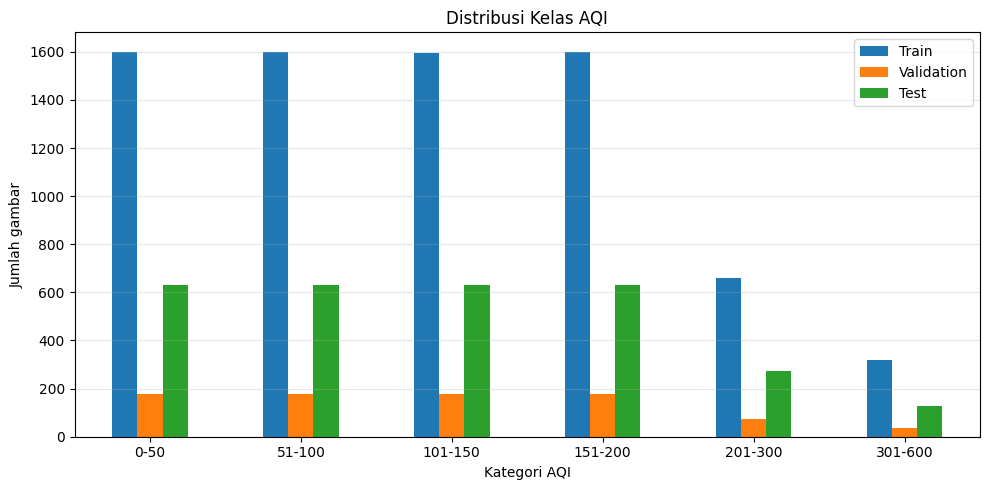

In [4]:
# Jumlah data dan distribusi kelas
for name, df in [('Train', train_meta), ('Validation', val_meta), ('Test', test_meta)]:
    print(f'{name}: {len(df):,} gambar')

    display(
        df['pm25_bin'].value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
        .rename('Jumlah gambar').to_frame()
    )

# Visualisasi
distribution = pd.DataFrame({
    'Train': train_meta['pm25_bin'].value_counts().reindex(CLASS_NAMES, fill_value=0),
    'Validation': val_meta['pm25_bin'].value_counts().reindex(CLASS_NAMES, fill_value=0),
    'Test': test_meta['pm25_bin'].value_counts().reindex(CLASS_NAMES, fill_value=0)
})

distribution.plot(kind='bar', figsize=(10, 5))
plt.title('Distribusi Kelas AQI')
plt.xlabel('Kategori AQI')
plt.ylabel('Jumlah gambar')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#  Preprocessing

In [5]:
# Koreksi orientasi berdasarkan metadata EXIF
def load_image_corrected(path):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img)
        return img.convert('RGB')


# Color Constancy - Gray World
def apply_gray_world(img_bgr):
    img = img_bgr.astype(np.float32)

    mean_b = img[..., 0].mean()
    mean_g = img[..., 1].mean()
    mean_r = img[..., 2].mean()

    mean_gray = (mean_b + mean_g + mean_r) / 3.0

    img[..., 0] = np.clip(
        img[..., 0] * (mean_gray / (mean_b + 1e-6)), 0, 255
    )
    img[..., 1] = np.clip(
        img[..., 1] * (mean_gray / (mean_g + 1e-6)), 0, 255
    )
    img[..., 2] = np.clip(
        img[..., 2] * (mean_gray / (mean_r + 1e-6)), 0, 255
    )

    return img.astype(np.uint8)


# Image Denoising - Non-Local Means (NLM)
def apply_denoise(img_bgr):
    return cv2.fastNlMeansDenoisingColored(
        img_bgr,
        None,
        h=6,
        hColor=6,
        templateWindowSize=7,
        searchWindowSize=21
    )


# Sharpness Enhancement - Unsharp Masking
def apply_unsharp_mask(img_bgr, sigma=1.0, strength=0.5):
    blurred = cv2.GaussianBlur(img_bgr, (0, 0), sigma)
    sharpened = cv2.addWeighted(
        img_bgr, 1 + strength,
        blurred, -strength,
        0
    )
    return np.clip(sharpened, 0, 255).astype(np.uint8)


# Resize: sisi pendek 232 piksel, lalu center crop 224 x 224
def resize_crop(pil_img):
    w, h = pil_img.size
    scale = RESIZE_SHORT_SIDE / min(w, h)

    out = pil_img.resize(
        (int(w * scale), int(h * scale)),
        Image.Resampling.BILINEAR
    )

    left = (out.width - IMG_SIZE) // 2
    top = (out.height - IMG_SIZE) // 2

    return out.crop((
        left, top,
        left + IMG_SIZE, top + IMG_SIZE
    ))


# Pipeline preprocessing
def preprocess_pipeline(pil_img):
    img_bgr = cv2.cvtColor(
        np.array(pil_img), cv2.COLOR_RGB2BGR
    )

    img_bgr = apply_gray_world(img_bgr)
    img_bgr = apply_denoise(img_bgr)
    img_bgr = apply_unsharp_mask(img_bgr)

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    return resize_crop(Image.fromarray(img_rgb))


# Normalisasi tensor menggunakan statistik ImageNet
to_tensor_normalize = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

## Cache Preprocessing

In [6]:
def cache_path(split, filename):
    name = os.path.splitext(str(filename))[0]
    return os.path.join(CACHE_DIR, split, name + '.png')

# Preprocessing dan menyimpan gambar ke cache
def cache_one(src, dst):
    if os.path.exists(dst):
        return None
    try:
        img = preprocess_pipeline(load_image_corrected(src))
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        img.save(dst, format='PNG')
    except Exception as e:
        return f'{src}: {e}'
        
# Membuat cache
def build_cache(df, split, images_dir):
    os.makedirs(os.path.join(CACHE_DIR, split), exist_ok=True)
    jobs = [
        (os.path.join(images_dir, fn), cache_path(split, fn))
        for fn in df['filename']
    ]
    todo = [(src, dst) for src, dst in jobs if not os.path.exists(dst)]
    print(f'[{split}] total: {len(jobs)} | Ada: {len(jobs)-len(todo)} | diproses: {len(todo)}')

    errors = []
    with ThreadPoolExecutor(max_workers=min(os.cpu_count() or 1, 6)) as pool:
        tasks = [pool.submit(cache_one, src, dst) for src, dst in todo]
        for task in tqdm(as_completed(tasks), total=len(tasks), desc=f'Cache {split}'):
            if error := task.result():
                errors.append(error)

    print(f'[{split}] selesai | gagal={len(errors)}')
    for error in errors[:10]:
        print(error)
    return errors

# Membuat cache untuk train, validation, dan test
if USE_CACHE:
    train_rows = pd.concat([train_meta, val_meta], ignore_index=True)

    errors = build_cache(train_rows, 'train', os.path.join(TRAIN_DIR, 'images'))
    errors += build_cache(test_meta, 'test', os.path.join(TEST_DIR, 'images'))

    if errors:
        print(f'PERINGATAN: {len(errors)} gambar gagal diproses.')

[train] total: 8194 | Ada: 0 | diproses: 8194


Cache train: 100%|███████████████████████████████████████████████████████████| 8194/8194 [1:27:41<00:00,  1.56it/s]


[train] selesai | gagal=0
[test] total: 2920 | Ada: 0 | diproses: 2920


Cache test: 100%|██████████████████████████████████████████████████████████████| 2920/2920 [31:14<00:00,  1.56it/s]

[test] selesai | gagal=0


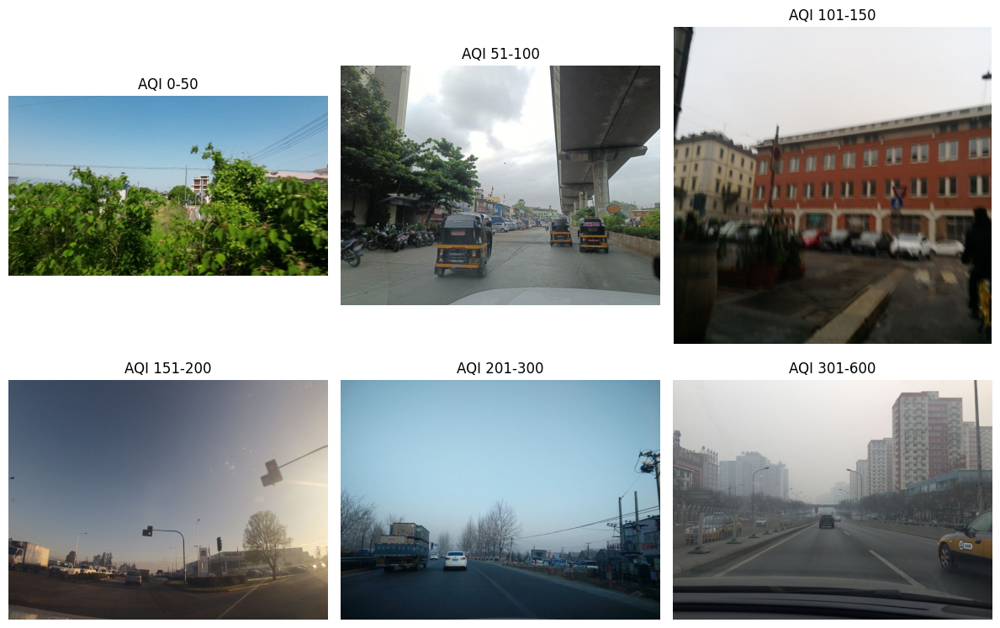

In [7]:
# Contoh gambar asli
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, label in zip(axes.flat, CLASS_NAMES):
    sample = train_meta[train_meta['pm25_bin'] == label].iloc[0]
    path = os.path.join(TRAIN_DIR, 'images', sample['filename'])

    ax.imshow(load_image_corrected(path))
    ax.set_title(f'AQI {label}')
    ax.axis('off')

plt.tight_layout()
plt.show()

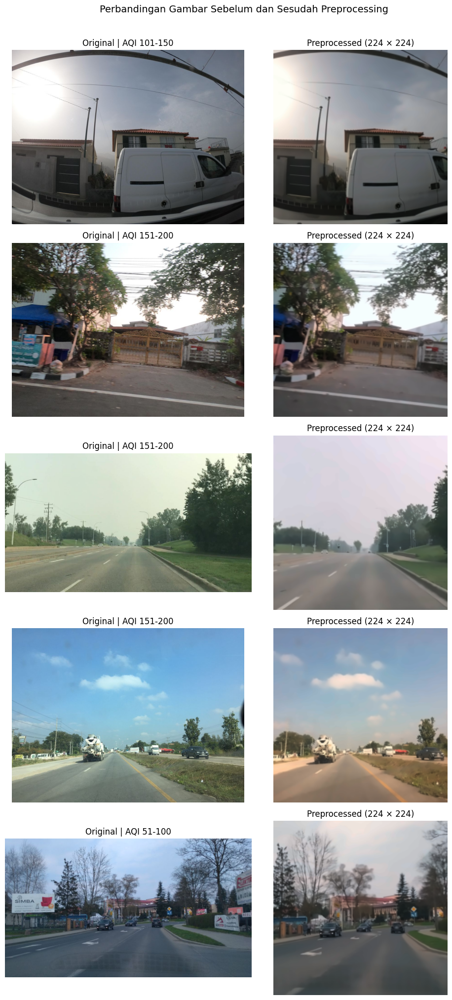

In [8]:
# Mengambil sampel dari dataset training
samples = train_meta.sample(
    n=min(5, len(train_meta)),
    random_state=RANDOM_SEED
).reset_index(drop=True)

fig, axes = plt.subplots(
    len(samples), 2,
    figsize=(10, 4 * len(samples))
)

for i, (_, sample) in enumerate(samples.iterrows()):
    path = os.path.join(TRAIN_DIR, 'images', sample['filename'])
    # Gambar sebelum preprocessing
    original = load_image_corrected(path)
    # Gambar setelah preprocessing
    processed = preprocess_pipeline(original)
    axes[i, 0].imshow(original)
    axes[i, 0].set_title(
        f"Original | AQI {sample['pm25_bin']}"
    )
    axes[i, 0].axis('off')
    axes[i, 1].imshow(processed)
    axes[i, 1].set_title(
        f"Preprocessed ({IMG_SIZE} × {IMG_SIZE})"
    )
    axes[i, 1].axis('off')

plt.suptitle(
    'Perbandingan Gambar Sebelum dan Sesudah Preprocessing',
    fontsize=14,
    y=1.01
)
plt.tight_layout()
plt.show()

# Dataset (Data Loader)

In [9]:
# Dataset pakai gambar di cache
if USE_CACHE:
    train_meta = train_meta[train_meta['filename'].apply(lambda f: os.path.exists(cache_path('train', f)))].copy()
    val_meta = val_meta[val_meta['filename'].apply(lambda f: os.path.exists(cache_path('train', f)))].copy()
    test_meta = test_meta[test_meta['filename'].apply(lambda f: os.path.exists(cache_path('test', f)))].copy()
    
# Dataset AQI untuk membaca gambar dan label
class AQIDataset(Dataset):
    def __init__(self, df, images_dir, split):
        self.df = df.reset_index(drop=True)
        self.images_dir = images_dir
        self.split = split
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        if USE_CACHE:
            path = cache_path(self.split, row['filename'])
            image = Image.open(path).convert('RGB')
        else:
            path = os.path.join(self.images_dir, row['filename'])
            image = preprocess_pipeline(load_image_corrected(path))
        image = to_tensor_normalize(image)
        label = CLASS_TO_IDX[row['pm25_bin']]
        return image, label


# Membuat dataset train, val, test
train_dataset = AQIDataset(train_meta, os.path.join(TRAIN_DIR, 'images'), 'train')
val_dataset = AQIDataset(val_meta, os.path.join(TRAIN_DIR, 'images'), 'train')
test_dataset = AQIDataset(test_meta, os.path.join(TEST_DIR, 'images'), 'test')

# DataLoader untuk training dan evaluasi
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)
train_eval_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)
print(f'Train={len(train_dataset)} | Validation={len(val_dataset)} | Test={len(test_dataset)}')
print(f'Batch train={len(train_loader)} | train-eval={len(train_eval_loader)} | val={len(val_loader)} | test={len(test_loader)}')

Train=7374 | Validation=820 | Test=2920
Batch train=231 | train-eval=231 | val=26 | test=92


# Class Weight

In [10]:
# Ubah kategori AQI jadi indeks kelas
train_labels = train_dataset.df['pm25_bin'].map(CLASS_TO_IDX).to_numpy()

# Hitung bobot setiap kelas menggunakan metode balanced
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_labels
)

# Ubah bobot kelas menjadi tensor PyTorch
class_weights = torch.tensor(
    class_weights, dtype=torch.float32, device=DEVICE
)

print('Class weights:')
for name, weight in zip(CLASS_NAMES, class_weights.cpu().tolist()):
    print(f'{name:>8}: {weight:.4f}')

# Pakai class weight pada fungsi loss Cross Entropy
criterion = nn.CrossEntropyLoss(weight=class_weights)

Class weights:
    0-50: 0.7676
  51-100: 0.7676
 101-150: 0.7705
 151-200: 0.7686
 201-300: 1.8678
 301-600: 3.8406


# Model

In [11]:
# Build ResNet50 pretrained ImageNet dengan output 6 kelas AQI
def build_resnet50():
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model
    
# Atur layer yang dibekukan dan dilatih pada setiap eksperimen
def configure_trainable_layers(model, mode):
    for param in model.parameters():
        param.requires_grad = False
    # Train fully connected layer pada semua eksperimen
    for param in model.fc.parameters():
        param.requires_grad = True

    # Fine-tuning Conv5_x
    if mode in ('conv5x', 'conv4x_conv5x'):
        for param in model.layer4.parameters():
            param.requires_grad = True
            
    # Fine-tuning Conv4_x dan Conv5_x
    if mode == 'conv4x_conv5x':
        for param in model.layer3.parameters():
            param.requires_grad = True
    return model

# Freeze statistik Batch Normalization pretrained
def freeze_batchnorm_stats(model):
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()

# Atur mode training dan Freeze Batch Normalization
def set_training_mode(model, mode):
    model.train()
    freeze_batchnorm_stats(model)
    # Menonaktifkan mode training pada blok yang dibekukan
    frozen_stages = ['conv1', 'bn1', 'layer1', 'layer2']
    if mode == 'baseline':
        frozen_stages += ['layer3', 'layer4']
    elif mode == 'conv5x':
        frozen_stages += ['layer3']
    for name in frozen_stages:
        getattr(model, name).eval()

# Hitung total parameter dan parameter yang dilatih
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

# Simpan checkpoint model terbaik
def save_checkpoint(path, model, mode, epoch, best_val_macro_f1, best_val_acc, history):
    payload = {
        'model_state_dict': model.state_dict(),
        'model_name': 'ResNet50',
        'experiment': mode,
        'epoch': int(epoch),
        'best_val_macro_f1': float(best_val_macro_f1),
        'best_val_acc': float(best_val_acc),
        'class_names': CLASS_NAMES,
        'img_size': IMG_SIZE,
        'preprocessing': [
            'EXIF transpose',
            'Gray World color constancy',
            'Non-Local Means denoising',
            'Unsharp masking',
            'resize-short-side-232',
            'center-crop-224',
            'ImageNet normalization'
        ],
        'history': history
    }

    temp_path = path + '.tmp'
    torch.save(payload, temp_path)
    os.replace(temp_path, path)

In [12]:
def evaluate_model(model, loader, criterion, desc='Evaluasi'):
    model.eval()
    total_loss = 0.0
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc=desc, leave=False):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * images.size(0)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(logits.argmax(1).cpu().numpy())

    avg_loss = total_loss / max(1, len(loader.dataset))
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

    return avg_loss, acc, macro_f1, np.array(y_true), np.array(y_pred)

In [13]:
# Train model  satu epoch
def train_one_epoch(model, loader, criterion, optimizer, mode, epoch, total_epochs):
    set_training_mode(model, mode)
    total_loss = 0.0
    y_true, y_pred = [], []
    progress = tqdm(loader, desc=f'{mode} | Epoch {epoch}/{total_epochs} train')

    for images, labels in progress:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        y_true.extend(labels.detach().cpu().numpy())
        y_pred.extend(logits.detach().argmax(1).cpu().numpy())
        progress.set_postfix(loss=f'{loss.item():.4f}')

    avg_loss = total_loss / max(1, len(loader.dataset))
    acc = accuracy_score(y_true, y_pred)
    return avg_loss, acc

In [14]:
# Run eksperimen training dan menyimpan model terbaik
def run_training_experiment(
    mode, model, trainable_layer_names, checkpoint_path,
    epochs=NUM_EPOCHS, patience=PATIENCE,
):
    model = configure_trainable_layers(model, mode)

    model = model.to(DEVICE)
    total_params, trainable_params = count_parameters(model)

    print(f'Eksperimen: {mode}')
    print(f'Parameter total: {total_params:,} | trainable: {trainable_params:,}')
    print('Layer trainable:', trainable_layer_names)
    print(f'Device: {DEVICE} | Epoch: {epochs} | Patience: {patience}\n')

    # Atur optimizer dan learning rate setiap eksperimen
    if mode == 'baseline':
        optimizer = torch.optim.Adam(
            [p for p in model.parameters() if p.requires_grad],
            lr=LEARNING_RATE_BASELINE
        )
    else:
        if mode == 'conv5x':
            groups = [
                {'params': model.layer4.parameters(), 'lr': LEARNING_RATE_BACKBONE},
                {'params': model.fc.parameters(), 'lr': LEARNING_RATE_FC}
            ]
        elif mode == 'conv4x_conv5x':
            groups = [
                {'params': model.layer3.parameters(), 'lr': LEARNING_RATE_BACKBONE / 3},
                {'params': model.layer4.parameters(), 'lr': LEARNING_RATE_BACKBONE},
                {'params': model.fc.parameters(), 'lr': LEARNING_RATE_FC}
            ]
        optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

    # Turunkan learning rate jika val Macro F1 tidak meningkat
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.2,
        patience=2, min_lr=1e-7
    )

    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': [],
        'val_macro_f1': [], 'lr': []
    }

    best_val_f1 = -1.0
    best_val_acc = 0.0
    best_train_loss = 0.0
    best_train_acc = 0.0
    best_val_loss = 0.0
    best_epoch = 0
    no_improvement = 0

    # Training dan validasi pada setiap epoch
    for epoch in range(1, epochs + 1):
        start = time.time()

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, mode, epoch, epochs
        )

        val_loss, val_acc, val_f1, _, _ = evaluate_model(
            model, val_loader, criterion,
            desc=f'{mode} | Epoch {epoch}/{epochs} validation'
        )

        scheduler.step(val_f1)

        history['train_loss'].append(float(train_loss))
        history['train_acc'].append(float(train_acc))
        history['val_loss'].append(float(val_loss))
        history['val_acc'].append(float(val_acc))
        history['val_macro_f1'].append(float(val_f1))
        history['lr'].append(float(optimizer.param_groups[-1]['lr']))

        # Menyimpan checkpoint berdasarkan Validation Macro F1 terbaik
        if val_f1 > best_val_f1:
            best_val_f1 = float(val_f1)
            best_val_acc = float(val_acc)
            best_val_loss = float(val_loss)
            best_train_loss = float(train_loss)
            best_train_acc = float(train_acc)
            best_epoch = epoch
            no_improvement = 0

            save_checkpoint(
                checkpoint_path, model, mode, best_epoch,
                best_val_f1, best_val_acc, history
            )
            note = 'checkpoint terbaik disimpan'
        else:
            no_improvement += 1
            note = ''

        elapsed = (time.time() - start) / 60

        # Menampilkan hasil training setiap epoch dalam beberapa baris
        print(f'\n{mode} Epoch {epoch:02d}/{epochs}:')
        print(f'train loss={train_loss:.4f}')
        print(f'train acc={train_acc:.4f}')
        print(f'val loss={val_loss:.4f}')
        print(f'val acc={val_acc:.4f}')
        print(f'val macro-F1={val_f1:.4f}')
        print(f'lr={optimizer.param_groups[-1]["lr"]:.2e}')
        print(f'{elapsed:.1f} menit')

        if note:
            print(note)

        # Early stopping sesuai val Macro F1
        if no_improvement >= patience:
            print(f'\nEarly stopping pada epoch {epoch}; terbaik={best_epoch}.')
            break

    # Memuat bobot model terbaik
    checkpoint = torch.load(
        checkpoint_path, map_location=DEVICE, weights_only=False
    )
    model.load_state_dict(checkpoint['model_state_dict'])

    # Ringkasan metrik dari epoch terbaik
    print(f'\nRingkasan Model Terbaik ({mode}):')
    print(f'Best epoch: {best_epoch}')
    print(f'Train Loss: {best_train_loss:.4f}')
    print(f'Train Accuracy: {best_train_acc:.4f}')
    print(f'Validation Loss: {best_val_loss:.4f}')
    print(f'Validation Accuracy: {best_val_acc:.4f}')
    print(f'Validation Macro F1: {best_val_f1:.4f}')

    return model, history


## Baseline ResNet50

In [15]:
baseline_path = os.path.join(CKPT_DIR, 'resnet50_baseline_best.pth')

# Train model ResNet50 baseline
torch.manual_seed(RANDOM_SEED)
model_baseline, history_baseline = run_training_experiment(
    mode='baseline',
    model=build_resnet50(),
    trainable_layer_names=['fc'],
    checkpoint_path=baseline_path
)

# Riwayat training setiap epoch
pd.DataFrame(history_baseline).rename_axis('epoch').assign(epoch=lambda df: df.index + 1).set_index('epoch').round(4)

Eksperimen: baseline
Parameter total: 23,520,326 | trainable: 12,294
Layer trainable: ['fc']
Device: cpu | Epoch: 50 | Patience: 5



baseline | Epoch 1/50 train: 100%|██████████████████████████████████| 231/231 [06:56<00:00,  1.80s/it, loss=1.7079]
                                                                                                                   


baseline Epoch 01/50:
train loss=1.7502
train acc=0.2697
val loss=1.6861
val acc=0.3220
val macro-F1=0.3232
lr=1.00e-04
7.7 menit
checkpoint terbaik disimpan


baseline | Epoch 2/50 train: 100%|██████████████████████████████████| 231/231 [06:29<00:00,  1.69s/it, loss=1.5547]
                                                                                                                   


baseline Epoch 02/50:
train loss=1.6609
train acc=0.3446
val loss=1.6128
val acc=0.3476
val macro-F1=0.3559
lr=1.00e-04
7.1 menit
checkpoint terbaik disimpan


...

baseline | Epoch 17/50 train: 100%|█████████████████████████████████| 231/231 [05:40<00:00,  1.47s/it, loss=1.1380]
                                                                                                                   


baseline Epoch 17/50:
train loss=1.3315
train acc=0.4924
val loss=1.3732
val acc=0.4085
val macro-F1=0.4132
lr=4.00e-06
6.3 menit


baseline | Epoch 18/50 train: 100%|█████████████████████████████████| 231/231 [05:42<00:00,  1.48s/it, loss=1.3286]
                                                                                                                   


baseline Epoch 18/50:
train loss=1.3311
train acc=0.4935
val loss=1.3726
val acc=0.4098
val macro-F1=0.4132
lr=4.00e-06
6.3 menit

Early stopping pada epoch 18; terbaik=13.

Ringkasan Model Terbaik (baseline):
Best epoch: 13
Train Loss: 1.3481
Train Accuracy: 0.4852
Validation Loss: 1.3829
Validation Accuracy: 0.4159
Validation Macro F1: 0.4172


,train_loss,train_acc,val_loss,val_acc,val_macro_f1,lr
epoch,,,,,,
1,1.7502,0.2697,1.6861,0.3220,0.3232,0.0001
2,1.6609,0.3446,1.6128,0.3476,0.3559,0.0001
3,1.5936,0.3735,1.5585,0.3610,0.3654,0.0001
4,1.5416,0.3933,1.5170,0.3756,0.3782,0.0001
5,1.4994,0.4113,1.4833,0.3902,0.3905,0.0001
6,1.4629,0.4231,1.4567,0.4073,0.4096,0.0001
7,1.4305,0.4428,1.4328,0.3951,0.4010,0.0001
8,1.4034,0.4533,1.4128,0.4061,0.4052,0.0001
9,1.3777,0.4680,1.3969,0.4122,0.4077,0.0000


## Fine-tuning Conv5_x

In [16]:
conv5_path = os.path.join(CKPT_DIR, 'resnet50_conv5x_best.pth')

# Train ResNet50 dengan fine-tuning Conv5_x
torch.manual_seed(RANDOM_SEED)
model_conv5, history_conv5 = run_training_experiment(
    mode='conv5x',
    model=build_resnet50(),
    trainable_layer_names=['layer4 (Conv5_x)', 'fc'],
    checkpoint_path=conv5_path,
)

# Riwayat training setiap epoch
pd.DataFrame(history_conv5).rename_axis('epoch').assign(epoch=lambda df: df.index + 1).set_index('epoch').round(4)

Eksperimen: conv5x
Parameter total: 23,520,326 | trainable: 14,977,030
Layer trainable: ['layer4 (Conv5_x)', 'fc']
Device: cpu | Epoch: 50 | Patience: 5



conv5x | Epoch 1/50 train: 100%|████████████████████████████████████| 231/231 [07:12<00:00,  1.87s/it, loss=1.4022]
                                                                                                                   


conv5x Epoch 01/50:
train loss=1.6083
train acc=0.3199
val loss=1.2964
val acc=0.4122
val macro-F1=0.4076
lr=1.00e-04
7.9 menit
checkpoint terbaik disimpan


conv5x | Epoch 2/50 train: 100%|████████████████████████████████████| 231/231 [07:16<00:00,  1.89s/it, loss=1.0911]
                                                                                                                   


conv5x Epoch 02/50:
train loss=1.1760
train acc=0.4863
val loss=1.1858
val acc=0.4451
val macro-F1=0.4811
lr=1.00e-04
7.9 menit
checkpoint terbaik disimpan


...

conv5x | Epoch 13/50 train: 100%|███████████████████████████████████| 231/231 [07:12<00:00,  1.87s/it, loss=0.0048]
                                                                                                                   


conv5x Epoch 13/50:
train loss=0.0058
train acc=1.0000
val loss=2.2055
val acc=0.5427
val macro-F1=0.5881
lr=2.00e-05
7.9 menit


conv5x | Epoch 14/50 train: 100%|███████████████████████████████████| 231/231 [07:13<00:00,  1.88s/it, loss=0.0072]
                                                                                                                   


conv5x Epoch 14/50:
train loss=0.0051
train acc=1.0000
val loss=2.2523
val acc=0.5402
val macro-F1=0.5845
lr=2.00e-05
7.9 menit

Early stopping pada epoch 14; terbaik=9.

Ringkasan Model Terbaik (conv5x):
Best epoch: 9
Train Loss: 0.1045
Train Accuracy: 0.9670
Validation Loss: 1.6664
Validation Accuracy: 0.5500
Validation Macro F1: 0.5950


,train_loss,train_acc,val_loss,val_acc,val_macro_f1,lr
epoch,,,,,,
1,1.6083,0.3199,1.2964,0.4122,0.4076,0.0001
2,1.1760,0.4863,1.1858,0.4451,0.4811,0.0001
3,0.9056,0.5829,1.0875,0.5073,0.5485,0.0001
4,0.6953,0.6770,1.0852,0.4988,0.5104,0.0001
5,0.5236,0.7555,1.1090,0.5463,0.5730,0.0001
6,0.3894,0.8205,1.3240,0.5256,0.5616,0.0001
7,0.2666,0.8889,1.3605,0.5476,0.5781,0.0001
8,0.1705,0.9364,1.4963,0.5366,0.5805,0.0001
9,0.1045,0.9670,1.6664,0.5500,0.5950,0.0001


## Fine-tuning Conv4_x + Conv5_x

In [17]:
conv4_conv5_path = os.path.join(CKPT_DIR, 'resnet50_conv4x_conv5x_best.pth')

# Train ResNet50 dengan fine-tuning Conv4_x dan Conv5_x
torch.manual_seed(RANDOM_SEED)
model_conv4_conv5, history_conv4_conv5 = run_training_experiment(
    mode='conv4x_conv5x',
    model=build_resnet50(),
    trainable_layer_names=['layer3 (Conv4_x)', 'layer4 (Conv5_x)', 'fc'],
    checkpoint_path=conv4_conv5_path,
)

# Riwayat training setiap epoch
pd.DataFrame(history_conv4_conv5).rename_axis('epoch').assign(epoch=lambda df: df.index + 1).set_index('epoch').round(4)

Eksperimen: conv4x_conv5x
Parameter total: 23,520,326 | trainable: 22,075,398
Layer trainable: ['layer3 (Conv4_x)', 'layer4 (Conv5_x)', 'fc']
Device: cpu | Epoch: 50 | Patience: 5



conv4x_conv5x | Epoch 1/50 train: 100%|█████████████████████████████| 231/231 [09:45<00:00,  2.53s/it, loss=1.3514]
                                                                                                                   


conv4x_conv5x Epoch 01/50:
train loss=1.5786
train acc=0.3293
val loss=1.2484
val acc=0.4134
val macro-F1=0.4244
lr=1.00e-04
10.4 menit
checkpoint terbaik disimpan


conv4x_conv5x | Epoch 2/50 train: 100%|█████████████████████████████| 231/231 [09:43<00:00,  2.53s/it, loss=1.0323]
                                                                                                                   


conv4x_conv5x Epoch 02/50:
train loss=1.1174
train acc=0.5054
val loss=1.1579
val acc=0.4500
val macro-F1=0.4920
lr=1.00e-04
10.4 menit
checkpoint terbaik disimpan


...

conv4x_conv5x | Epoch 23/50 train: 100%|████████████████████████████| 231/231 [09:42<00:00,  2.52s/it, loss=0.0004]
                                                                                                                   


conv4x_conv5x Epoch 23/50:
train loss=0.0005
train acc=1.0000
val loss=2.7982
val acc=0.5793
val macro-F1=0.6158
lr=4.00e-06
10.3 menit


conv4x_conv5x | Epoch 24/50 train: 100%|████████████████████████████| 231/231 [09:42<00:00,  2.52s/it, loss=0.0006]
                                                                                                                   


conv4x_conv5x Epoch 24/50:
train loss=0.0005
train acc=1.0000
val loss=2.8037
val acc=0.5793
val macro-F1=0.6160
lr=4.00e-06
10.3 menit

Early stopping pada epoch 24; terbaik=19.

Ringkasan Model Terbaik (conv4x_conv5x):
Best epoch: 19
Train Loss: 0.0006
Train Accuracy: 1.0000
Validation Loss: 2.7442
Validation Accuracy: 0.5793
Validation Macro F1: 0.6160


,train_loss,train_acc,val_loss,val_acc,val_macro_f1,lr
epoch,,,,,,
1,1.5786,0.3293,1.2484,0.4134,0.4244,0.0001
2,1.1174,0.5054,1.1579,0.4500,0.4920,0.0001
3,0.8390,0.6187,1.0687,0.5037,0.5401,0.0001
4,0.6275,0.7049,1.0724,0.5024,0.5180,0.0001
5,0.4536,0.7916,1.1268,0.5634,0.5929,0.0001
6,0.3206,0.8552,1.2966,0.5512,0.5830,0.0001
7,0.1937,0.9230,1.4089,0.5646,0.5905,0.0001
8,0.1069,0.9680,1.5571,0.5659,0.6112,0.0001
9,0.0511,0.9900,1.7546,0.5659,0.5947,0.0001


## Kurva Training

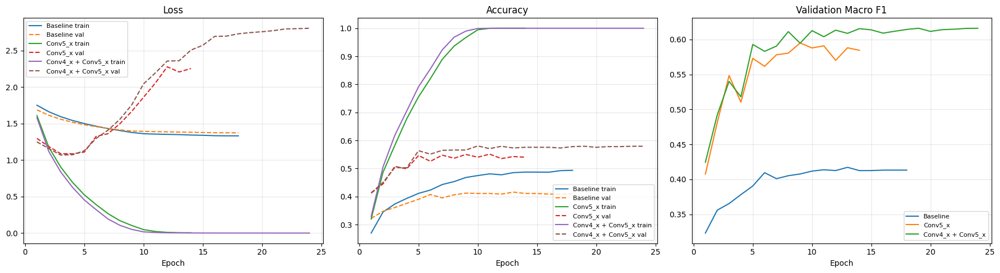

In [18]:
histories = {
    'Baseline': history_baseline,
    'Conv5_x': history_conv5,
    'Conv4_x + Conv5_x': history_conv4_conv5
}

# Grafik Loss, Accuracy, dan Validation Macro F1
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, hist in histories.items():
    epochs = range(1, len(hist['train_loss']) + 1)
    for metric, ax in [('loss', axes[0]), ('acc', axes[1])]:
        ax.plot(epochs, hist[f'train_{metric}'], label=f'{name} train')
        ax.plot(epochs, hist[f'val_{metric}'], '--', label=f'{name} val')
    axes[2].plot(epochs, hist['val_macro_f1'], label=name)

for ax, title in zip(axes, ['Loss', 'Accuracy', 'Validation Macro F1']):
    ax.set(title=title, xlabel='Epoch')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'training_curves.png'), dpi=200, bbox_inches='tight')
plt.show()

# Evaluasi

In [19]:
# Evaluasi model, save Classification Report & Confusion Matrix
def evaluate_and_save(model, loader, split, experiment, output_dir):
    loss, acc, macro_f1, y_true, y_pred = evaluate_model(
        model, loader, criterion, desc=f'{experiment} | {split}'
    )

    # Classification Report
    report = classification_report(
        y_true, y_pred, labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES, zero_division=0, digits=4
    )
    report_df = pd.DataFrame(classification_report(
        y_true, y_pred, labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES, zero_division=0, output_dict=True
    )).T
    report_df.to_csv(
        os.path.join(output_dir, f'{experiment}_{split}_classification_report.csv')
    )

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    cm_df = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)
    cm_df.to_csv(
        os.path.join(output_dir, f'{experiment}_{split}_confusion_matrix.csv')
    )

    print(f'\n{experiment.upper()} — {split.upper()}')
    print(f'Loss: {loss:.4f} | Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f}')
    print(report)

    # Visualisasi Confusion Matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix — {experiment} — {split}')
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, f'{experiment}_{split}_confusion_matrix.png'),
        dpi=180, bbox_inches='tight'
    )
    plt.show()
    plt.close()

    return {
        'experiment': experiment,
        'split': split,
        'loss': loss,
        'accuracy': acc,
        'macro_precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'macro_recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'macro_f1': macro_f1,
        'report': report_df,
        'confusion_matrix': cm_df,
        'y_true': y_true,
        'y_pred': y_pred
    }


Evaluasi baseline | Best epoch: 13



BASELINE — TRAIN
Loss: 1.3443 | Accuracy: 0.4868 | Macro F1: 0.4825
              precision    recall  f1-score   support

        0-50     0.5165    0.5871    0.5495      1601
      51-100     0.4673    0.3210    0.3806      1601
     101-150     0.4856    0.4031    0.4406      1595
     151-200     0.5625    0.5235    0.5423      1599
     201-300     0.4600    0.6474    0.5379       658
     301-600     0.3212    0.7188    0.4440       320

    accuracy                         0.4868      7374
   macro avg     0.4689    0.5335    0.4825      7374
weighted avg     0.4956    0.4868    0.4821      7374



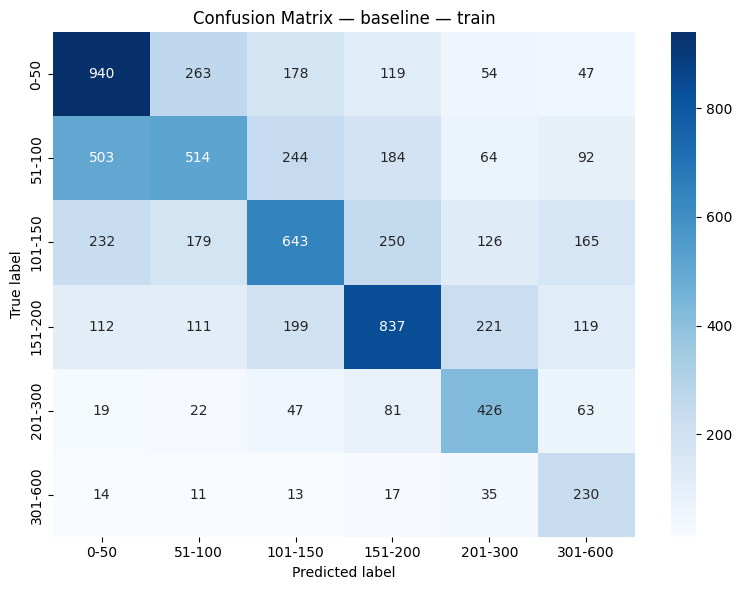


BASELINE — VALIDATION
Loss: 1.3829 | Accuracy: 0.4159 | Macro F1: 0.4172
              precision    recall  f1-score   support

        0-50     0.4400    0.4944    0.4656       178
      51-100     0.3500    0.1966    0.2518       178
     101-150     0.4218    0.3503    0.3827       177
     151-200     0.4821    0.4551    0.4682       178
     201-300     0.4032    0.6849    0.5076        73
     301-600     0.3086    0.6944    0.4274        36

    accuracy                         0.4159       820
   macro avg     0.4010    0.4793    0.4172       820
weighted avg     0.4166    0.4159    0.4039       820



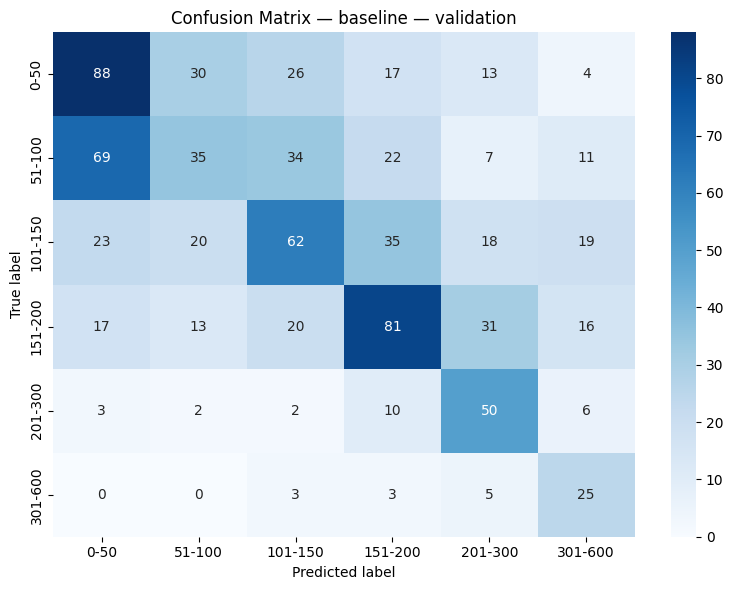


BASELINE — TEST
Loss: 1.6404 | Accuracy: 0.3408 | Macro F1: 0.2938
              precision    recall  f1-score   support

        0-50     0.4571    0.5676    0.5064       629
      51-100     0.3552    0.2238    0.2746       630
     101-150     0.3293    0.2587    0.2898       630
     151-200     0.3722    0.4000    0.3856       630
     201-300     0.1862    0.2364    0.2083       275
     301-600     0.0769    0.1349    0.0980       126

    accuracy                         0.3408      2920
   macro avg     0.2962    0.3036    0.2938      2920
weighted avg     0.3473    0.3408    0.3379      2920



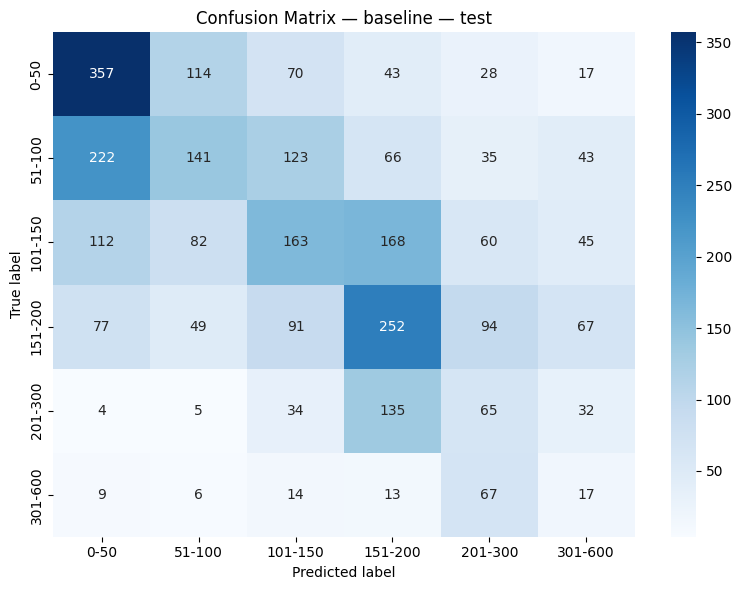


Evaluasi conv5x | Best epoch: 9



CONV5X — TRAIN
Loss: 0.0554 | Accuracy: 0.9948 | Macro F1: 0.9960
              precision    recall  f1-score   support

        0-50     0.9888    0.9931    0.9910      1601
      51-100     0.9937    0.9831    0.9884      1601
     101-150     0.9938    1.0000    0.9969      1595
     151-200     1.0000    1.0000    1.0000      1599
     201-300     1.0000    1.0000    1.0000       658
     301-600     1.0000    1.0000    1.0000       320

    accuracy                         0.9948      7374
   macro avg     0.9960    0.9960    0.9960      7374
weighted avg     0.9949    0.9948    0.9948      7374



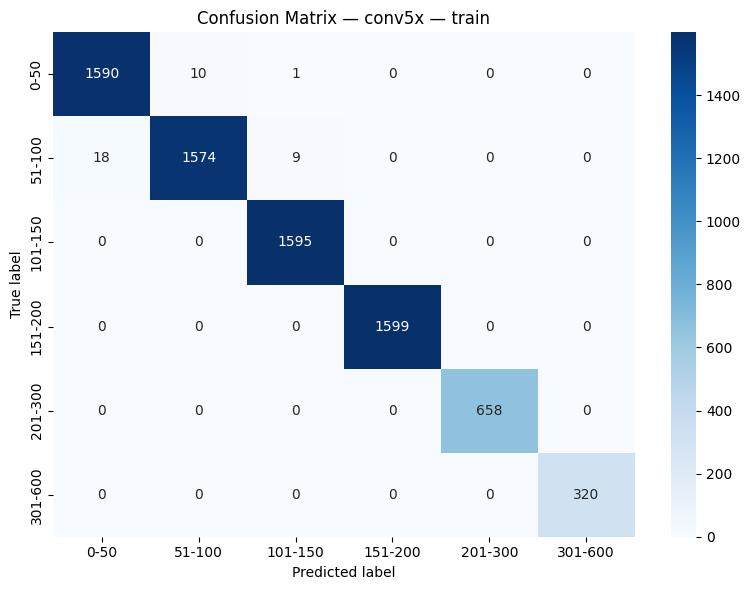


CONV5X — VALIDATION
Loss: 1.6664 | Accuracy: 0.5500 | Macro F1: 0.5950
              precision    recall  f1-score   support

        0-50     0.5249    0.5337    0.5292       178
      51-100     0.4000    0.2697    0.3221       178
     101-150     0.4407    0.6723    0.5324       177
     151-200     0.7278    0.6461    0.6845       178
     201-300     0.7778    0.6712    0.7206        73
     301-600     0.8929    0.6944    0.7812        36

    accuracy                         0.5500       820
   macro avg     0.6273    0.5812    0.5950       820
weighted avg     0.5623    0.5500    0.5468       820



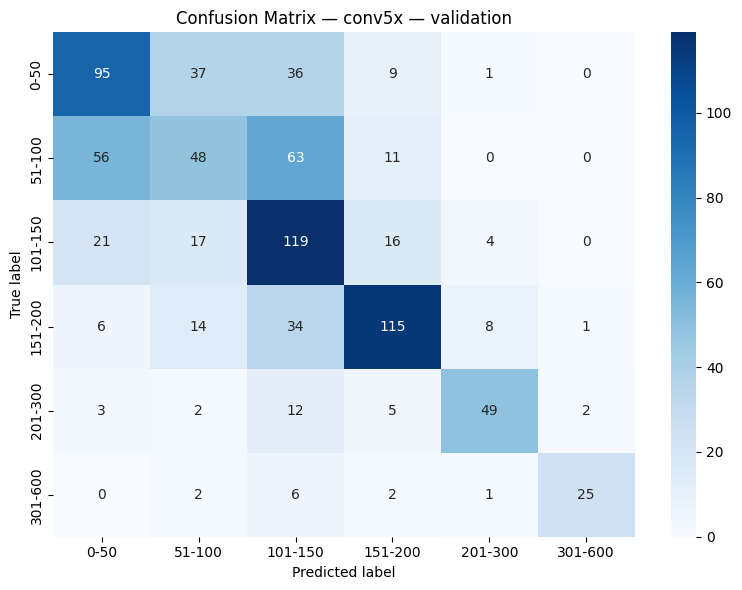


CONV5X — TEST
Loss: 3.7204 | Accuracy: 0.3784 | Macro F1: 0.3325
              precision    recall  f1-score   support

        0-50     0.4917    0.5660    0.5262       629
      51-100     0.3416    0.2841    0.3102       630
     101-150     0.3281    0.4984    0.3957       630
     151-200     0.3685    0.3048    0.3336       630
     201-300     0.3046    0.1673    0.2160       275
     301-600     0.4186    0.1429    0.2130       126

    accuracy                         0.3784      2920
   macro avg     0.3755    0.3272    0.3325      2920
weighted avg     0.3767    0.3784    0.3672      2920



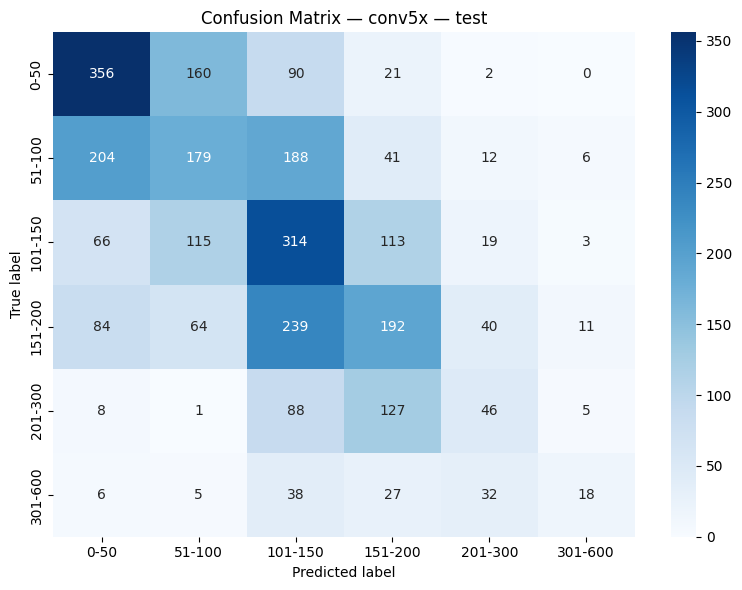


Evaluasi conv4x_conv5x | Best epoch: 19



CONV4X_CONV5X — TRAIN
Loss: 0.0006 | Accuracy: 1.0000 | Macro F1: 1.0000
              precision    recall  f1-score   support

        0-50     1.0000    1.0000    1.0000      1601
      51-100     1.0000    1.0000    1.0000      1601
     101-150     1.0000    1.0000    1.0000      1595
     151-200     1.0000    1.0000    1.0000      1599
     201-300     1.0000    1.0000    1.0000       658
     301-600     1.0000    1.0000    1.0000       320

    accuracy                         1.0000      7374
   macro avg     1.0000    1.0000    1.0000      7374
weighted avg     1.0000    1.0000    1.0000      7374



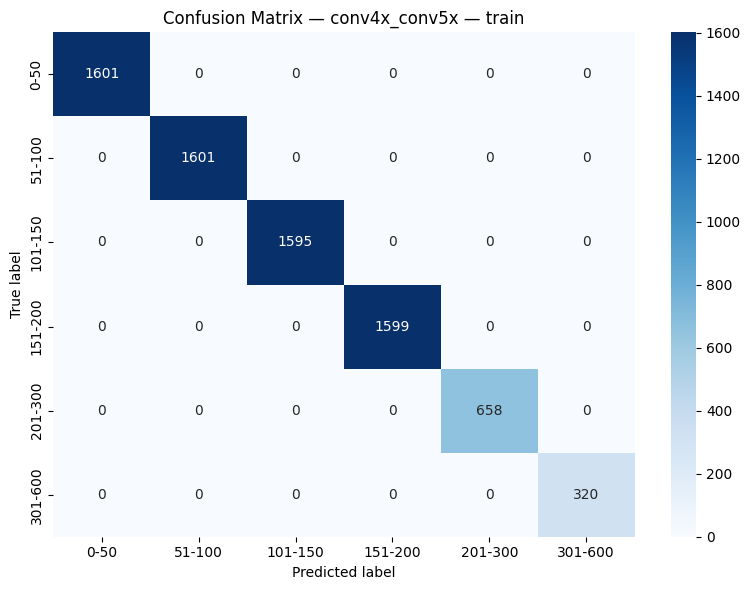


CONV4X_CONV5X — VALIDATION
Loss: 2.7442 | Accuracy: 0.5793 | Macro F1: 0.6160
              precision    recall  f1-score   support

        0-50     0.5509    0.5169    0.5333       178
      51-100     0.4551    0.3989    0.4251       178
     101-150     0.4955    0.6158    0.5491       177
     151-200     0.6995    0.7191    0.7091       178
     201-300     0.7647    0.7123    0.7376        73
     301-600     0.8846    0.6389    0.7419        36

    accuracy                         0.5793       820
   macro avg     0.6417    0.6003    0.6160       820
weighted avg     0.5841    0.5793    0.5788       820



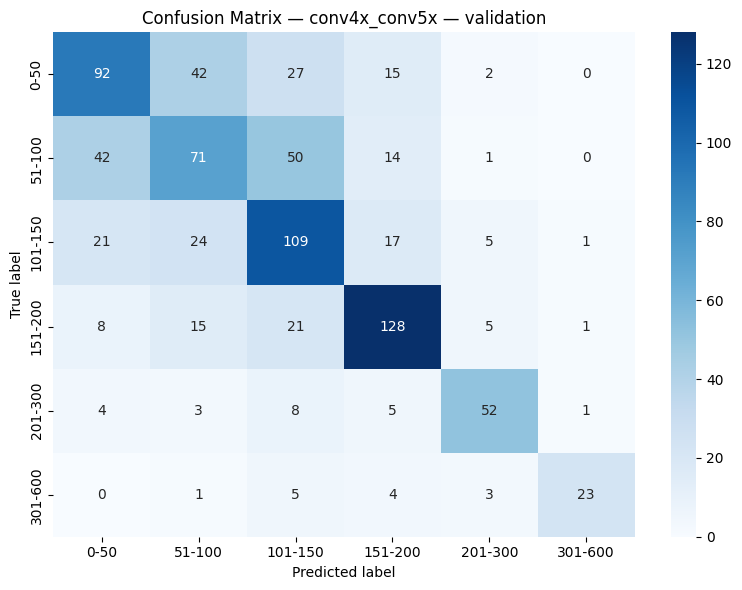


CONV4X_CONV5X — TEST
Loss: 6.1086 | Accuracy: 0.3935 | Macro F1: 0.3528
              precision    recall  f1-score   support

        0-50     0.5029    0.5564    0.5283       629
      51-100     0.3519    0.3921    0.3709       630
     101-150     0.3697    0.3984    0.3835       630
     151-200     0.3642    0.3619    0.3631       630
     201-300     0.3190    0.1891    0.2374       275
     301-600     0.3889    0.1667    0.2333       126

    accuracy                         0.3935      2920
   macro avg     0.3828    0.3441    0.3528      2920
weighted avg     0.3894    0.3935    0.3873      2920



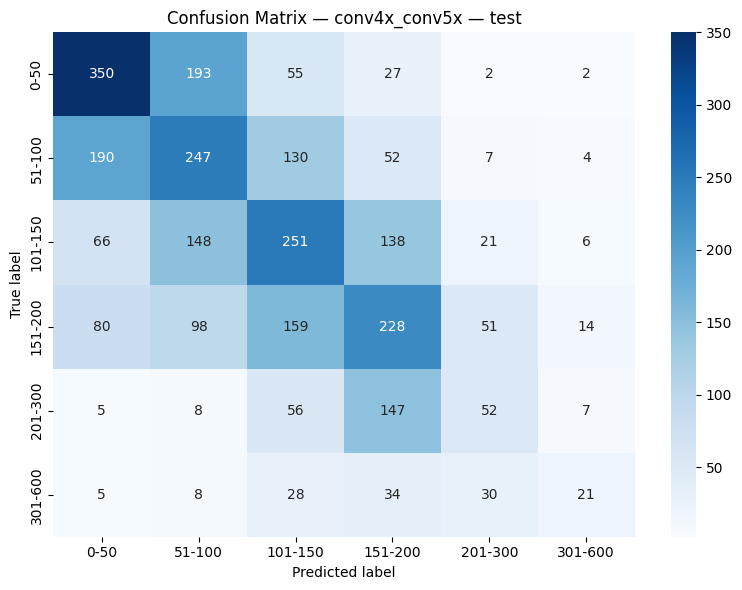

,Experiment,Split,Best Epoch,Best Validation Macro F1,Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
0,baseline,train,13,0.4172,1.3443,0.4868,0.4689,0.5335,0.4825
1,baseline,validation,13,0.4172,1.3829,0.4159,0.4010,0.4793,0.4172
2,baseline,test,13,0.4172,1.6404,0.3408,0.2962,0.3036,0.2938
3,conv5x,train,9,0.5950,0.0554,0.9948,0.9960,0.9960,0.9960
4,conv5x,validation,9,0.5950,1.6664,0.5500,0.6273,0.5812,0.5950
5,conv5x,test,9,0.5950,3.7204,0.3784,0.3755,0.3272,0.3325
6,conv4x_conv5x,train,19,0.6160,0.0006,1.0000,1.0000,1.0000,1.0000
7,conv4x_conv5x,validation,19,0.6160,2.7442,0.5793,0.6417,0.6003,0.6160
8,conv4x_conv5x,test,19,0.6160,6.1086,0.3935,0.3828,0.3441,0.3528


Ringkasan save di: D:\Kuliah\STA TA\Fix STA\results\summary_all_splits.csv


In [20]:
# Daftar checkpoint
experiment_specs = [
    ('baseline', baseline_path),
    ('conv5x', conv5_path),
    ('conv4x_conv5x', conv4_conv5_path)
]

evaluation_results = {}
summary_rows = {}

# Evaluasi eksperimen pada train, val, dan test
for experiment, path in experiment_specs:
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    model = build_resnet50().to(DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f'\nEvaluasi {experiment} | Best epoch: {checkpoint["epoch"]}')

    for split, loader in [
        ('train', train_eval_loader),
        ('validation', val_loader),
        ('test', test_loader)
    ]:
        result = evaluate_and_save(model, loader, split, experiment, RESULTS_DIR)
        evaluation_results[(experiment, split)] = result
        summary_rows[(experiment, split)] = {
            'Experiment': experiment,
            'Split': split,
            'Best Epoch': checkpoint['epoch'],
            'Best Validation Macro F1': checkpoint['best_val_macro_f1'],
            'Loss': result['loss'],
            'Accuracy': result['accuracy'],
            'Macro Precision': result['macro_precision'],
            'Macro Recall': result['macro_recall'],
            'Macro F1': result['macro_f1']
        }

# Simpan ringkasan hasil evaluasi
summary_df = pd.DataFrame(summary_rows.values())
summary_path = os.path.join(RESULTS_DIR, 'summary_all_splits.csv')
summary_df.to_csv(summary_path, index=False)

display(summary_df.round(4))
print('Ringkasan save di:', summary_path)

# Save Model

In [21]:
print('Checkpoint terbaik:')

for _, path in experiment_specs:
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)
    print(
        f'{os.path.basename(path)} | '
        f'Epoch: {checkpoint["epoch"]} | '
        f'Val Accuracy: {checkpoint["best_val_acc"]:.4f} | '
        f'Val Macro F1: {checkpoint["best_val_macro_f1"]:.4f} | '
    )
print('\nFolder checkpoint:', CKPT_DIR)
print('Folder hasil evaluasi:', RESULTS_DIR)
print('Urutan kelas:', CLASS_NAMES)

Checkpoint terbaik:
resnet50_baseline_best.pth | Epoch: 13 | Val Accuracy: 0.4159 | Val Macro F1: 0.4172 | 
resnet50_conv5x_best.pth | Epoch: 9 | Val Accuracy: 0.5500 | Val Macro F1: 0.5950 | 
resnet50_conv4x_conv5x_best.pth | Epoch: 19 | Val Accuracy: 0.5793 | Val Macro F1: 0.6160 | 

Folder checkpoint: D:\Kuliah\STA TA\Fix STA\checkpoints
Folder hasil evaluasi: D:\Kuliah\STA TA\Fix STA\results
Urutan kelas: ['0-50', '51-100', '101-150', '151-200', '201-300', '301-600']


In [22]:
full_model_specs = [
    ('baseline', model_baseline),
    ('conv5x', model_conv5),
    ('conv4x_conv5x', model_conv4_conv5)
]

for name, model in full_model_specs:
    save_path = os.path.join(CKPT_DIR, f'resnet50_{name}_full.pth')
    torch.save(model.cpu(), save_path)
    model.to(DEVICE)
    print(f'Model lengkap disimpan: {save_path}')

Model lengkap disimpan: D:\Kuliah\STA TA\Fix STA\checkpoints\resnet50_baseline_full.pth
Model lengkap disimpan: D:\Kuliah\STA TA\Fix STA\checkpoints\resnet50_conv5x_full.pth
Model lengkap disimpan: D:\Kuliah\STA TA\Fix STA\checkpoints\resnet50_conv4x_conv5x_full.pth


In [23]:
MODEL_PATH = os.path.join(
    CKPT_DIR, 'resnet50_conv5x_full.pth'
)

model_prediksi = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model_prediksi = model_prediksi.to(DEVICE)
model_prediksi.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [24]:
def prediksi_aqi(nama_file):
    # Baca gambar asli
    image_path = os.path.join(BASE_DIR, nama_file)
    original = load_image_corrected(image_path)
    # Preprocessing sesuai pipeline training
    processed = preprocess_pipeline(original)
    print('Gambar Sebelum Preprocessing:')
    display(original)
    print('Gambar Sesudah Preprocessing:')
    display(processed)

    # Ubah gambar menjadi tensor dan normalisasi ImageNet
    input_tensor = to_tensor_normalize(processed).unsqueeze(0).to(DEVICE)
    # Melakukan prediksi
    with torch.no_grad():
        logits = model_prediksi(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0]
    # Mengambil tiga prediksi dengan probabilitas tertinggi
    top_probs, top_indices = torch.topk(
        probabilities, k=min(3, len(CLASS_NAMES))
    )
    print('\nHasil Prediksi Top 3:')
    for rank, (prob, idx) in enumerate(
        zip(top_probs.cpu().tolist(), top_indices.cpu().tolist()),
        start=1
    ):
        print(f'{rank}. AQI {CLASS_NAMES[idx]}: {prob * 100:.2f}%')

    return {
        'nama_file': nama_file,
        'prediksi': CLASS_NAMES[int(top_indices[0].item())],
        'confidence': float(top_probs[0].item()) * 100
    }

Gambar Sebelum Preprocessing:


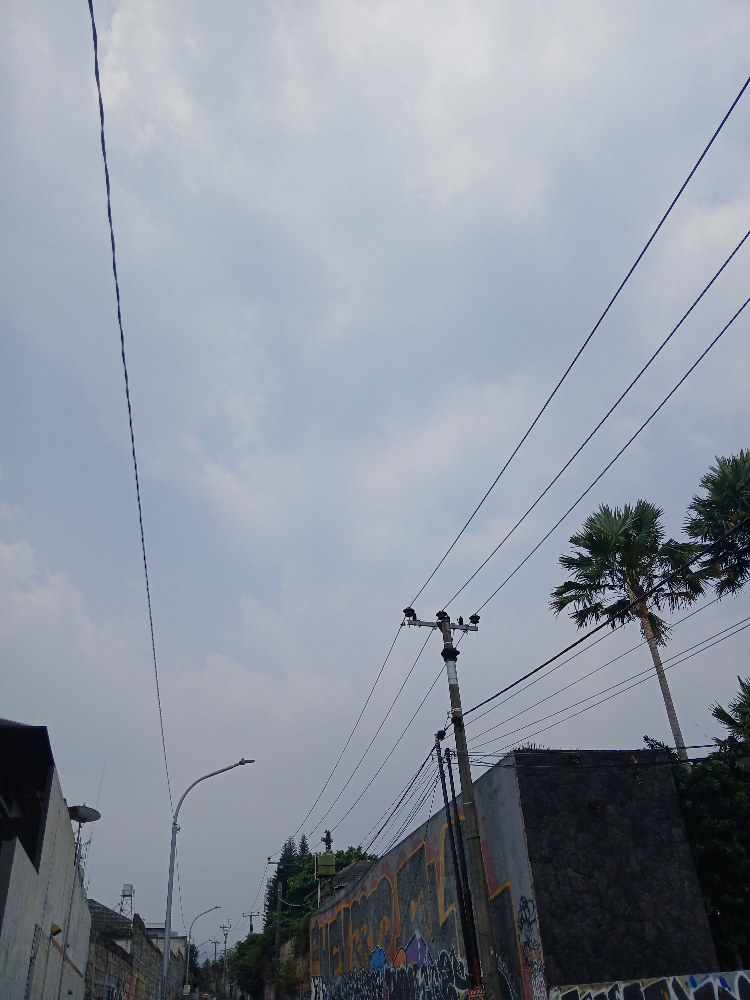

Gambar Sesudah Preprocessing:


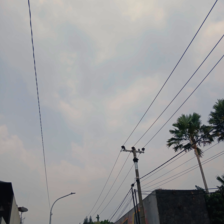


Hasil Prediksi Top 3:
1. AQI 201-300: 66.54%
2. AQI 151-200: 15.05%
3. AQI 51-100: 6.33%


In [25]:
hasil = prediksi_aqi('cth 151 200.jpg')

Gambar Sebelum Preprocessing:


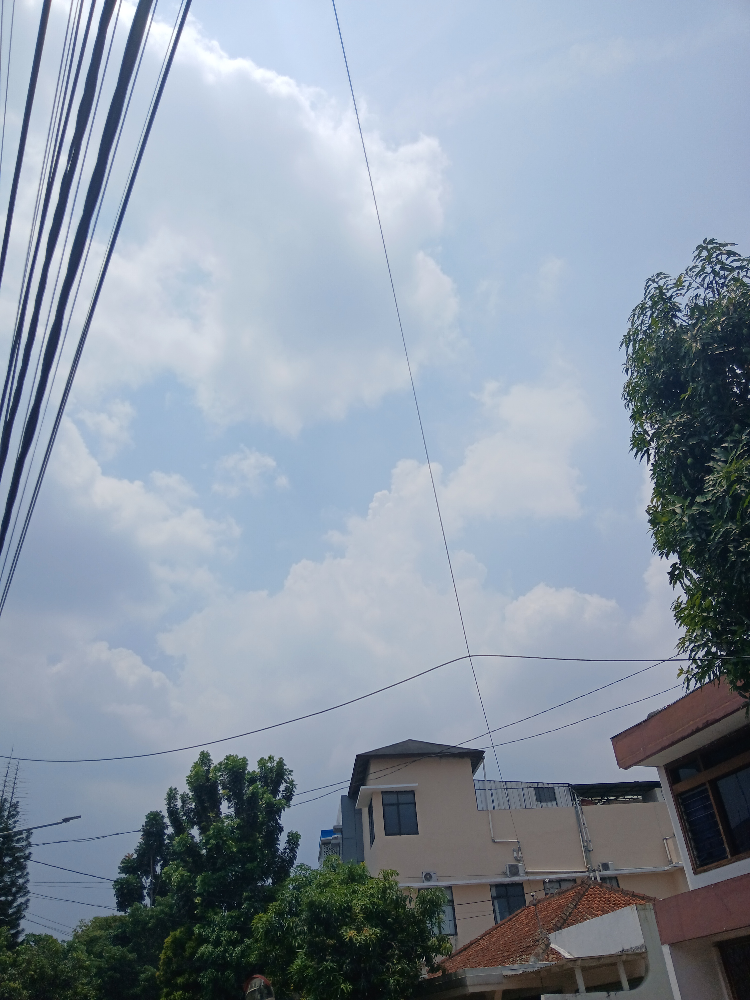

Gambar Sesudah Preprocessing:


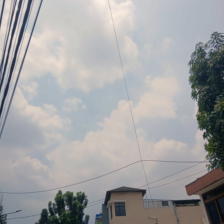


Hasil Prediksi Top 3:
1. AQI 201-300: 94.48%
2. AQI 301-600: 4.05%
3. AQI 51-100: 0.61%


In [26]:
hasil = prediksi_aqi('101 150.jpg')

Gambar Sebelum Preprocessing:


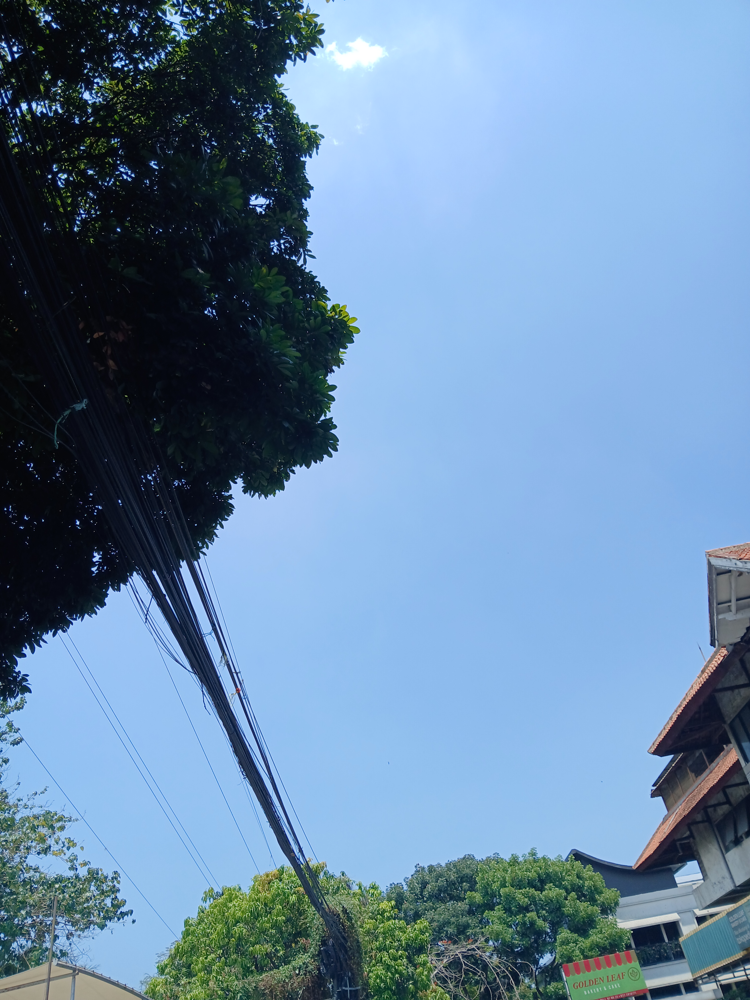

Gambar Sesudah Preprocessing:


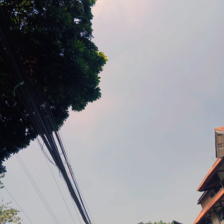


Hasil Prediksi Top 3:
1. AQI 151-200: 35.59%
2. AQI 301-600: 26.26%
3. AQI 101-150: 22.35%


In [27]:
hasil = prediksi_aqi('51 100.jpg')

Gambar Sebelum Preprocessing:


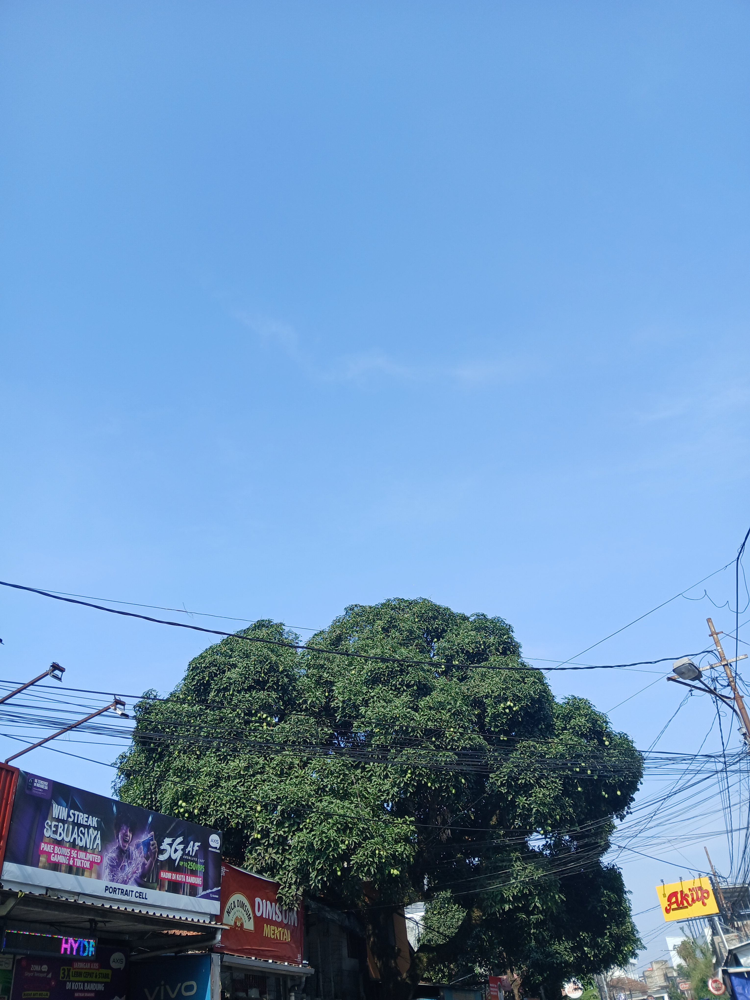

Gambar Sesudah Preprocessing:


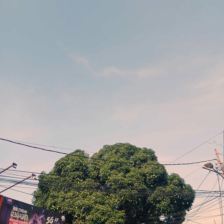


Hasil Prediksi Top 3:
1. AQI 201-300: 68.91%
2. AQI 301-600: 26.69%
3. AQI 101-150: 3.50%


In [28]:
hasil = prediksi_aqi('a 101 150.jpg')

Gambar Sebelum Preprocessing:


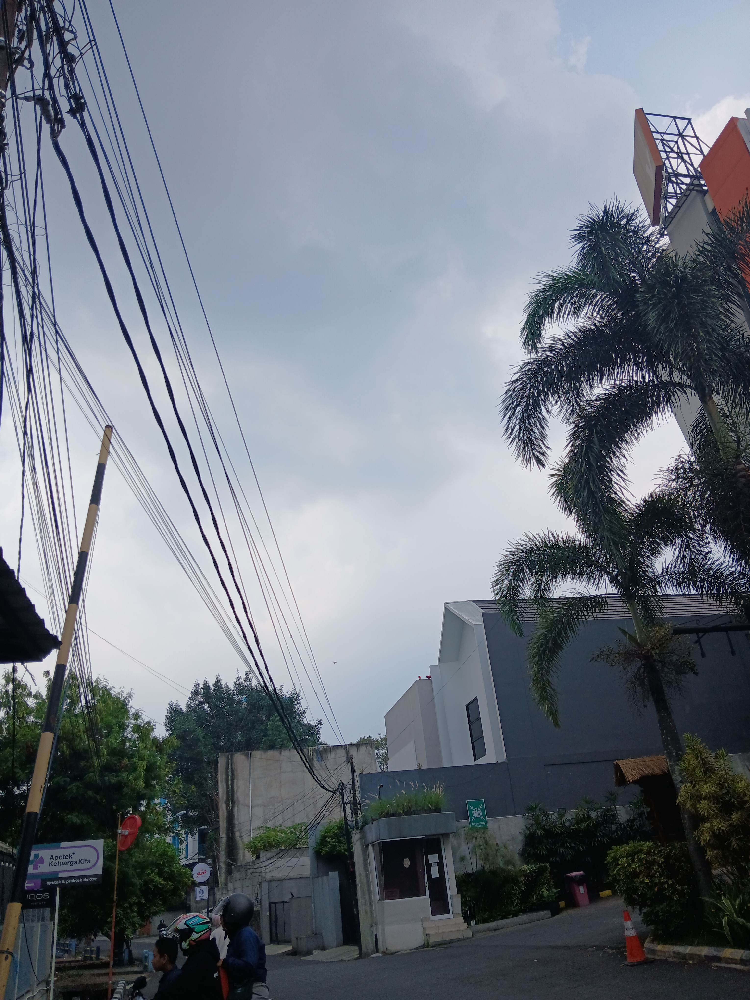

Gambar Sesudah Preprocessing:


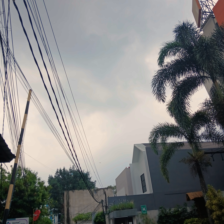


Hasil Prediksi Top 3:
1. AQI 101-150: 92.25%
2. AQI 301-600: 5.11%
3. AQI 51-100: 1.35%


In [29]:
hasil = prediksi_aqi('a 51 100.jpg')

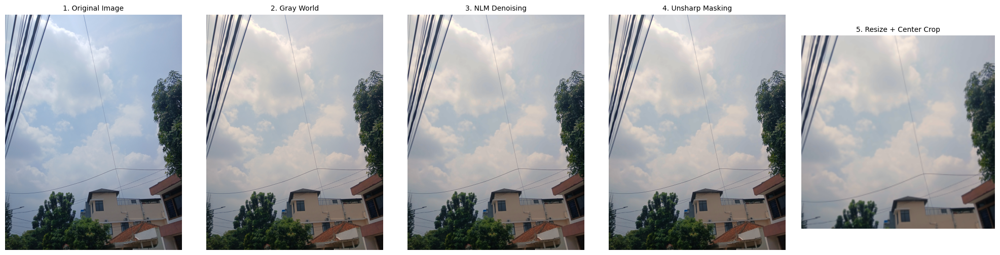

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
from PIL import Image, ImageOps

# Pilih satu gambar asli dari dataset
image_path = "101 150.jpg"

# 1. Load image dan koreksi orientasi EXIF
original_pil = load_image_corrected(image_path)

# Konversi RGB ke BGR seperti pipeline asli
img_bgr = cv2.cvtColor(
    np.array(original_pil),
    cv2.COLOR_RGB2BGR
)

# 2. Color Constancy - Gray World
gray_world_bgr = apply_gray_world(img_bgr)

# 3. Image Denoising - Non-Local Means
denoised_bgr = apply_denoise(gray_world_bgr)

# 4. Sharpness Enhancement - Unsharp Masking
unsharp_bgr = apply_unsharp_mask(denoised_bgr)

# 5. Resize
unsharp_rgb = cv2.cvtColor(
    unsharp_bgr,
    cv2.COLOR_BGR2RGB
)

resized_pil = resize_crop(Image.fromarray(unsharp_rgb))

# Daftar tahapan untuk visualisasi
stages = [
    ("1. Original Image", original_pil),
    ("2. Gray World", cv2.cvtColor(gray_world_bgr, cv2.COLOR_BGR2RGB)),
    ("3. NLM Denoising", cv2.cvtColor(denoised_bgr, cv2.COLOR_BGR2RGB)),
    ("4. Unsharp Masking", unsharp_rgb),
    ("5. Resize + Center Crop", resized_pil)
]

# Visualisasi
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (title, img) in zip(axes, stages):
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()